In [6]:
def find_repeating_substrings(s):
    """
    Find all maximal substrings of length 4+ that appear more than once.
    A substring is excluded if it's fully contained within every occurrence
    of a longer repeating substring.

    Returns a dict mapping each repeating substring to a list of
    starting indices where it occurs.
    """
    n = len(s)
    all_repeats = {}

    for length in range(4, n):
        for i in range(n - length + 1):
            sub = s[i:i + length]
            if sub not in all_repeats:
                all_repeats[sub] = []
            all_repeats[sub].append(i)

    # Keep only substrings that actually repeat
    repeats = {sub: idx for sub, idx in all_repeats.items() if len(idx) > 1}

    # Filter out non-maximal substrings: remove a substring if every one of
    # its occurrences is contained within an occurrence of a longer repeat.
    to_remove = set()
    for sub, indices in repeats.items():
        for longer, longer_indices in repeats.items():
            if len(longer) <= len(sub) or longer == sub:
                continue
            # Check if every occurrence of `sub` falls inside an occurrence of `longer`
            if all(
                any(li <= si and si + len(sub) <= li + len(longer)
                    for li in longer_indices)
                for si in indices
            ):
                to_remove.add(sub)
                break

    return {sub: idx for sub, idx in repeats.items() if sub not in to_remove}

In [2]:
find_repeating_substrings('abcdefjhkjrhtkehrtkjhabcdef')

{'abcdef': [0, 21]}

In [7]:
group1 = "ZVNNF TROEB UKXZB AELGN VZRRZ DRJRP BHSQG TFBNT RAGEU QEZPE RZYWY KWQYR VLJOK PGNVM AJJWS CFZZY RVQGE WBFPA ZKCTA UIGRZ RLEES IEKJI AJPPB RVEVZ YVBZY QAMZV VZKWF OKLBC EWAUI BBKRB VZNIF GYWOH ZBUUC MNTUB UGKUR GEAPU DNBXK QGNRL NVVZS KTBYE IWHTU LBUIT VQVIC UIBUU CMCGZ VGKUO EKVVJ OKPNY YQAEP MYRFE OXRAF QEWOO EBUKV FNIKU VJUTR ZYMQU FZBVV VRJFV GURBH HVAUG GMQNR TYRZS RGKCA TVTNB VZLIF USUIB NHCMG AEVRR NQGNF CGYDW XKNQG NGIAK CTRJN IYRJI AJWTB UIAGO CMQGE LPGIX RZVLC XFDVJ VLJOK PCUCQ FNVLP NRQEY RVQRF BFGEL YUKAB LGMTY WWENR BFGEL PURBF ZYMUU SJVZN IFLFV QUWDV YZBBX JBUKK CATVT JULVQ UEIAJ FVTUZ VTLRQ ERPJH ZEWGW LQGKJ BEGZO UZZVG UKPRY ZLRUW BUKYQ YRKPR NZTYG JIYRK PRVVW CRVNB XDIAE DQYKJ ZBAEL PGCTR JZBNT UUNTP TVZKT RXFCA JUWBX JWCKE MQULB BLZBS OIAGU EWAKJ QQKRV QZYMA UEIAU KPRXE WTUZV TAGAG GZZFL FZGNV PBHSQ GHVLE UFUFH RBUXF WZYTM YRRZF VRVGX ZMFRF BFUWB UKJMJ GILEU SMFNV PNJNP BRVZB UDAQK MWGKU BBICW GNVAX OKKUK EAQOE QAMIW BSJIY RNMEK FVGNV ANSVN YUFZN TUQAJ VMQUE BUKJI ZKGIF YRORZ YMOKJ BEUFU FCVZR GCTBT KPRRV NGNRV QYZLR MFQAM ZVSUI BUKJM JKIMG NVWAR PWAKJ BBNRD RCZVQ UNAQK VXFKK ZBAEL JOELB CJTBU BQAMF DRXYQ FMRZQ KEIAJ DMNJF EFHVG BTUAY UGQAM UWJTK WGNVZ VBVZ"
group2 = "AZONG XSOFF VKYDC AFPHN WDSRA HSJST CHTUH TGFOT SEHEV UFZQI SZZAZ KXUZR WPKOL THNWQ BJKAT CGDAY SZRGF ACFQE AKDXB UJKSZ SPFET MFKKM BJQTC RWIWZ ZZCZZ UBMAZ WZLAG OLPCC FABUJ FCKSF WZOMG GZAPH AFVUD QOTVF VGLYS GFEQU ERCXL UHNSP OVWDT KUFZE JAITV PCUJX WQWMD UJFVU DQDGA ZHKVS FKWZK OLTOY ZUBEQ QZRGI PXSEG QFAPO FFVKW JOILY WJVXS ZZQRU GDCVW ZSJGZ HUSFI HWEVG HQRNS XZRAW SGLGB TWXOB WDMIG YTUJF OHDQH AFZSR OUHNG GHYEA YKOUH NHMBK DXSJO MZRKM BJXXC UJEHO DQRGF PQGJB SZWPD XGHWJ WPKOL TDUDU GNWPQ NSUFY SZRRG FGGFP ZULEC LHQUY XAFNS FGGFP QUSFG ZZQVU TNWZO MGLGZ RUXHW YAFCX KFVKL GBTWX KUMZR UFMBJ GZUUA ZULSU FRQNI ZFAHW MUHKK FFGAS VZAZH ULTSY APSUX FVKZU ZRLTS NAXZG KMZRL TSVWA DRWRC XEMBE EUZKK DCAFP QGDXS JAFOT VYOTQ XWZLX SXGGB JVACX KADKF QRUMF CLAFT OJEHU FABKK URKSZ RZZQB UFMBU LTSXF AUUAZ UAHEH GADGL GDHNW TCHTU HHWPF UGYGH SFVXG AAYUQ ZRSDG VSZHX AQGRG FGUXF VKKQK GJPFU TQGNW TOJOT CRWDC UEERK NAHKV FCIDA HNWEY OLOVK FEROF UBMJA CSKMZ ROQFK GZHNW EOSWR ZUGDO TVUBJ WQRUF FVKKM AKHMG YSSSZ ZQPKK FFUGY GCWDS GDXCT LTSRW RHNSZ RYAPS MGUBM AZTUJ FVKKQ KKJQH NWABR QABKK FCNSH SCAZR UOERK WBGKL DCAFP KOFPC CKXCU CUBMG HSXZU GMSDR KFMBJ EQOJG IGHWK CTVEZ UHUBM VAKTL AHNWD WBWD"
group3 = "NEOKC QVWQH MVUUC ZERWV JISOW AVRDV TSPLH SFHDB FJHBR NIHBK JKVRZ JWWOZ JUKLH MKVHS SUGRT BFFPG FERDB TFNBG RVZOB TIMHH FUFBP FISVO SUMKC QVKLH MECWV NEULB NKHRG NKRRK SFBRF YFSDH NKKDG FYCEP NKVRZ JRBGH MRHPS FEGFC RWCUH NKVDR FGSUT JTHOM WFIQR IFCUZ NBSDD TIHKC QVDDW SKSGU WVSQK NKVDG MZBBM JCZRK GIOVG PECEW SKVHS CRQWA NUROS YYSGC TICSS SVRRB YFOWI GVGKO UVRKO QCZLY JRHXB SVZDJ JIMFC RWCUH FSZHH ZEBHZ BZHKC ZKGPC PVKLH MGOQS QCSGK FCZVO SUTOC TIGWW QVRDB ITOUD JKSGD WFJLR JUKLH MGCOW XYSGQ MRWUG FEROC YJOQR QFHVC KGSJG KFFKO YJOQR HFOWG YYSKC GSWWK FJTRB IFTYW XZHRF XKVHH ZEBHZ BFIQR TEOQR TEURW SXTDW WCMEI YECWE ZZHHG YIOLU MKWQH TKVHG NUSRT YYSKW QCHKS MZZOO XRZOH MVDHC UCSIC WDOQM RZZHG WFIQR HRZOS IZHDB IDOQM QZHWZ JICXB IUCRF XFDHB JUCXH TWWWT NIGWC SFBHG NUSDB IKVHB TEOQC YYSUB TXCLB LLDVH FZFVT TIHKS MFPEW YSSGF TFAVP FKVUC TDGFS QCOUG URBWF NVGOC YJCIH MVGHK FIRUC GVGKS MRRZV TCSUC TDGGS AFHHR YFQOC YYSVY NKQKS SJRLB NEUUC TDGDZ QNSUS TEHKS XRAHT QFCUO SUWQR JVRRB YYSVO RVDDG XRUHH MVPHG YICRA XNSUS FCZRB YYSOS KKVDB IJWGS LFWQU NETRF YYSVS BVFHH MVCQZ DFBHG YFVDJ JNWQR TNGGS JGGHH WFIQR BZBGC BJZRC PZBJC AVFKW XXOUR JEOQR RVOGC BJPHM TERVZ TGWQU IFKQH TKVHF NMSU"
group4 = "OVMSW RMUYB NMSCW AVPEP KZQWQ BMPLP UJNTB TWFLV GAFJL OZFJE KBTZT KNUWT KLITB NBTPM TLEZN CWDXA GVPLV UWLJA SMXWV UZKPB GLDJJ GZQDI TLKSW RMITB NVAEP OVSTV OBFZA OBPZE TWZZZ ZWQLB OBILA GPAMJ OBTZT KIZOB NIFXM GVENW SNACB OBTLL GXQCN KKFWG XWGYL JWACT OSQLX UZFSW RMBLQ TBQOO XMQYE OBTLA NQZJG KTXZE HZMDA QVAMQ TBTPM DIOEU OLPWM ZPQOW UZAAM TMPZV ZWMEC HMESI VMPSI RTXTS KIFFV TMXLD KZKNW SNACB GJXPB AVZPT CQFSW ABEXW QMITB NXMYM RTQOE GTXDI TLRWW UZEEQ RMPLV JKMCX KBQOX XWHTL KLITB NXAWQ YPQOK NIUCA GVPWW ZAMYL RWFDW LXQRA LWDSI ZAMYL IWMEA ZPQSW HJUEE GARZV JWRGQ YQFZZ YBTPB AVZPT CWGYL UVMYL UVSZQ TORLQ XTKMC ZVAEY AQFPA ZZMTO NBUYB UBTPA OLQZN ZPQSQ RTFSM NQXWI YIXWB NMBPW VTQQW XUMYG SQXPA XWGYL IIXWM JQFLV JUMYG RQFET KZAFV JLAZZ YWBPV KLAFB UNUEN OZEEW TWZPA OLQLV JBTPV UVMYW ZPQCV UOATV MCBDB GQDDN UZFSM NWNMQ ZJQOZ UWYDJ GBTCW UUENM RTMCA VIZEZ OMEWW ZAAQB NMEPE GZPCW HMESM NIPHP UTQCW UUEOM BWFPL ZWOWW ZPQDS OBOSM TAPTV OVSCW UUELT REQCM UVFSM YIYPN RWACI TLUYL KMPZV ZPQDI SMBLA YISPB NMNPA ZZAZU YEQCM GTXZV ZPQWM LBTLV JAUOM MWUYO OVRZZ ZPQDM CMDPB NMAYT EWZPA ZWTLD KEUYL UEEOM KXEPB XWGYL CQZOW CAXZW QQZRW BMDSQ YOMCL KVMYL SMMOW CANPG UVPDT UXUYO JWIYB UBTPZ ODQC"
group5 = "TRGVZ LWTRZ VPGJZ YTREH WCIRW GEVLL UPMIL YSZOY AKECJ WCTQH IZVZL WQMRZ PDOTX NHSEW YHYCQ WGCQY OYDSY SUNJS EPPRB ZRQPX GRCYT LVKGL NVJLU ZPWAE LTCEH AYKOB TTLZW OHOOO YSTCC TGPEZ WEWSD ENCMB AELUZ PAFOX NOEMW LRYQZ MXZVZ WEHSO EVSCF WNXRM COMYH JCZRD TOKOA OJELU ZPPST RZSOG JPITK TTZLW NWYYQ PPRCH BJLWY YYOTT RZVPE PLGZA TDVWI ZVPDG ZVUDP NWOST HZALF FKGSA HPHNO WLDTO KOEUF YIROG EJJGU AQOJE EHZPT MYRKZ HILSS AHDMG VICWE HHLRK ZWEVH ERZDA FOJRC ZRKEM RSOAF OGGFA ELPHV FZVAO IJKTT ZASRW DHWOG NOTRK LRJZZ TKLRJ ZZTKZ JVSRS XZVNO ESSYH ICLTK ELKVZ BTTXC ODFGY HUTGI KTXUF DTZPX ABYED HSABO OFLRJ CYGGT RMTLI JWCHI ENGEU AWEEK EVGWR HLTRZ CEHWD MJSZF LSINW WLLSI NWWLS DERZE HWAIU DWEXZ VSOYY ETPKG COMYH IOWLW OMZOY DELRE ZTTLW IXCFN VOSUF DOHPR KRZUL ZJOHQ IJDXU BZNWD MJSLN VELKB ZNSYS ZVPRF ZKUWY GMAWZ OTRKQ SXHSE ZZFHW EBWOV UCXST LXNFZ OEDGK ZWAJD TGBER APWRC ESGQX NSDEO LVJFZ BWDLK VLDOS SRSCO GXWJS GOLPH ZCNLG ELKGV ILNLK BDDAY MTUCO GXWGZ WWWCI UBEHW DESSQ LGZVG BOIFO IKRZN LSIYO XEHLW YOREL SIHSD TJZSS GHEJP ERZZN LSIRS QTZLR JGTDW RSOBR IFQSX HSEKP AKFPT ZPSTZ JOFPW ZCSAN PAOBO OODHK SASWE VUIYD OTRJC HSDZS QWYGG GIXVT SYLVJ SYAFO QKOOO ODFKM ZNVDP UDTNY OSCBE OLSIX WGEJ"

In [18]:
group4 = group4.replace(' ', '')

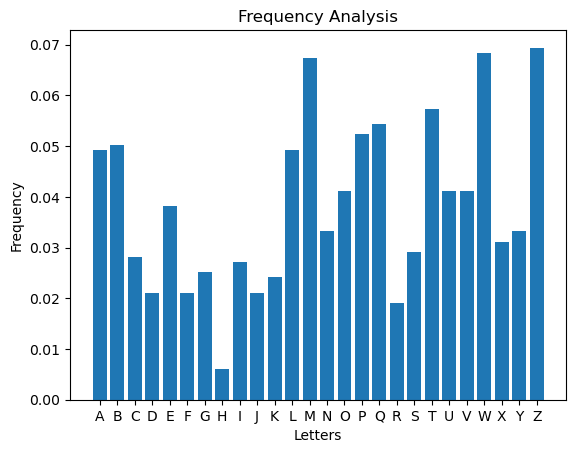

In [19]:
import matplotlib.pyplot as plt

LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
frequency = []

for char in LETTERS:
    frequency.append(group4.count(char) / len(group4))

plt.bar(list(LETTERS), frequency)
plt.xlabel('Letters')
plt.ylabel('Frequency')
plt.title('Frequency Analysis')

plt.show()

In [20]:
find_repeating_substrings(group4.replace(' ', ''))

{'SWRM': [3, 113, 218],
 'ITBN': [62, 117, 352, 402],
 'BTPM': [66, 261],
 'AGVP': [79, 419],
 'DITL': [108, 368],
 'OBTL': [185, 235],
 'WGYL': [201, 491, 586, 926],
 'UZFS': [215, 680],
 'HMES': [295, 740],
 'WWZA': [423, 723],
 'ZPQS': [455, 545],
 'YLUV': [493, 498],
 'UVMY': [495, 655],
 'VMYL': [496, 956],
 'PAZZ': [523, 843],
 'FSMN': [552, 682],
 'UMYG': [576, 601],
 'WZPA': [641, 901],
 'WZPQ': [659, 769],
 'ZPQD': [770, 825, 885],
 'EQCM': [796, 851],
 'PBNM': [838, 893],
 'OWCA': [933, 963],
 'BTZTK': [51, 161],
 'MITBN': [116, 351],
 'XWGYL': [200, 585, 925],
 'MPZVZ': [286, 821],
 'ITBNX': [352, 402],
 'ZAMYL': [425, 445],
 'PAOLQ': [538, 643],
 'CWUUE': [703, 753, 788],
 'ZVZPQ': [823, 858],
 'KLITBN': [60, 400],
 'YBUBTP': [533, 983],
 'NWSNACB': [178, 323],
 'PBAVZPTC': [333, 483]}

In [23]:
bucket1 = group4[0::5]
bucket1

'ORNAKBUTGOKKKNTCGUSUGGTRNOOOTZOGOKNGSOGKXJOURTXONKHQTDOZUTZHVRKTKSGACAQNRGTURJKXKNYNGZRLLZIZHGJYYACUUTXZAZNUOZRNYNVXSXIJJRKJYKUOTOJUZUMGUNZUGURVOZNGHNUUBZZOTOURUYRTKZSYNZYGZLJMOZCNEZKUKXCCQBYKSCUUJUO'

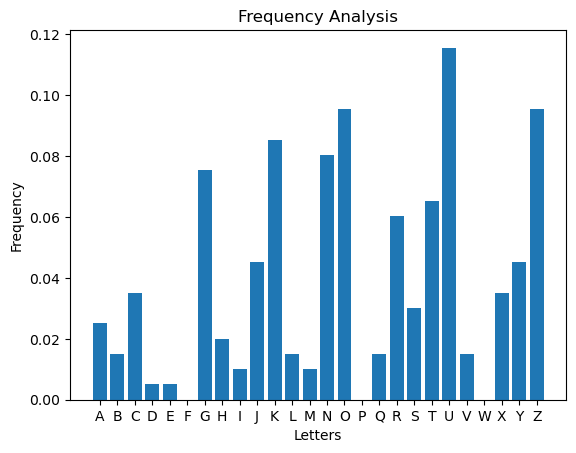

In [24]:
import matplotlib.pyplot as plt

LETTERS = 'ABCDEFGHIJKLMNOPQRSTUVWXYZ'
frequency = []

for char in LETTERS:
    frequency.append(bucket1.count(char) / len(bucket1))

plt.bar(list(LETTERS), frequency)
plt.xlabel('Letters')
plt.ylabel('Frequency')
plt.title('Frequency Analysis')

plt.show()